# Import Module

In [ ]:
from google.colab import drive
drive.mount('/content/drive')#---push to repo yopi andriyansah

Mounted at /content/drive


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Mempersiapkan Data

In [ ]:
# Daca data csv
df = pd.read_csv('/content/drive/MyDrive/Data Fluks/Data/raw_juni_seminggu.csv')

In [ ]:
# Mengubah "Timestamp" menjadi indeks
df['timestamp'] = pd.to_datetime(df['timestamp'])
df = df.set_index("timestamp")
df = df.sort_index()

In [ ]:
# Ubah nama kolom
df.rename(columns={'bmp388Pressure': 'Air Pressure (kPa)', 'bmp388Temp': 'Air Temperature (Celcius)', 'sht85Humi': 'Relatif Humidity (%)',
                   'sht85Temp': 'Temperature (Celsius)', 'co2': 'C02 mole fraction (µmol/mol_a)', 'bawah': 'bawah (m/s)', 'atas':'atas (m/s)',
                   'H2OSHT85':'Water Vapor Mass Density (kg/m^3)', 'bmp388ApprxAltitude': 'Altitude (MSAL)', 'ch4': 'CH4 mole fraction (µmol/mol_a)', 'utara':'utara (m/s)',
                   'barat': 'barat (m/s)', 'timur': 'timur (m/s)', 'selatan':'selatan (m/s)'}, inplace=True)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 1945487 entries, 2024-06-10 13:06:01.353000 to 2024-06-17 23:36:00.969000
Data columns (total 14 columns):
 #   Column                             Dtype  
---  ------                             -----  
 0   Air Pressure (kPa)                 float64
 1   Air Temperature (Celcius)          float64
 2   Altitude (MSAL)                    float64
 3   Relatif Humidity (%)               float64
 4   Temperature (Celsius)              float64
 5   C02 mole fraction (µmol/mol_a)     int64  
 6   CH4 mole fraction (µmol/mol_a)     int64  
 7   Water Vapor Mass Density (kg/m^3)  float64
 8   utara (m/s)                        float64
 9   barat (m/s)                        float64
 10  timur (m/s)                        float64
 11  selatan (m/s)                      float64
 12  bawah (m/s)                        float64
 13  atas (m/s)                         float64
dtypes: float64(12), int64(2)
memory usage: 222.6 MB


# Menghitung Parameter Meteorologi

- Parameter Mass Density of Air
  
  $ \rho_a = \frac{p}{R \times T} \quad [\mathrm{kg\ m^{-3}}] $



In [ ]:
R = 8.314472 # Konstanta gas universal (J/mol/K)
Md = 0.02897  # Massa Molekul Udara Kering (kg/mol)
Ra = R/Md # Konstanta udara (J/kg/K)
df['Temperature (K)'] = df["Temperature (Celsius)"] + 273.15 # Suhu (Kelvin)
df['Air Pressure (Pa)'] = df["Air Pressure (kPa)"] * 1000 # Tekanan udara (Pa)
df['Mass Density of Air (kg/m^3)'] = df['Air Pressure (Pa)']/(Ra* df['Temperature (K)']) # Densitas udara (mol/m³)

- Parameter Molar Density of Air

  $ \rho = \frac{p}{R \times T} \quad [\mathrm{mol\ m^{-3}}] $

In [ ]:
df['Molar Density of Air (mol/m^3)'] = df['Air Pressure (Pa)']/(R* df['Temperature (K)']) # Densitas udara (mol/m³)

df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 1945487 entries, 2024-06-10 13:06:01.353000 to 2024-06-17 23:36:00.969000
Data columns (total 18 columns):
 #   Column                             Dtype  
---  ------                             -----  
 0   Air Pressure (kPa)                 float64
 1   Air Temperature (Celcius)          float64
 2   Altitude (MSAL)                    float64
 3   Relatif Humidity (%)               float64
 4   Temperature (Celsius)              float64
 5   C02 mole fraction (µmol/mol_a)     int64  
 6   CH4 mole fraction (µmol/mol_a)     int64  
 7   Water Vapor Mass Density (kg/m^3)  float64
 8   utara (m/s)                        float64
 9   barat (m/s)                        float64
 10  timur (m/s)                        float64
 11  selatan (m/s)                      float64
 12  bawah (m/s)                        float64
 13  atas (m/s)                         float64
 14  Temperature (K)                    float64
 15  Air Pressure (Pa)  

- Parameter Molar Volume of Air
  
  $ v_a = \frac{R \times T}{p} \quad [\mathrm{m^{3}\ mol^{-1}}] $

In [ ]:
df["Molar Volume of Air (m^3/mol)"] = (R*df["Temperature (K)"])/df["Air Pressure (Pa)"]

df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 1945487 entries, 2024-06-10 13:06:01.353000 to 2024-06-17 23:36:00.969000
Data columns (total 19 columns):
 #   Column                             Dtype  
---  ------                             -----  
 0   Air Pressure (kPa)                 float64
 1   Air Temperature (Celcius)          float64
 2   Altitude (MSAL)                    float64
 3   Relatif Humidity (%)               float64
 4   Temperature (Celsius)              float64
 5   C02 mole fraction (µmol/mol_a)     int64  
 6   CH4 mole fraction (µmol/mol_a)     int64  
 7   Water Vapor Mass Density (kg/m^3)  float64
 8   utara (m/s)                        float64
 9   barat (m/s)                        float64
 10  timur (m/s)                        float64
 11  selatan (m/s)                      float64
 12  bawah (m/s)                        float64
 13  atas (m/s)                         float64
 14  Temperature (K)                    float64
 15  Air Pressure (Pa)  

- Parameter Saturation Vapor Pressure $e_s$ (kPa)

  $e_s(T) = 0.611 \cdot \exp\left( \frac{17.502 \cdot T}{T + 240.97} \right) \quad [\text{kPa}]$

In [ ]:
df['Saturation Vapor Pressure (kPa)'] = 0.611 * np.exp((17.502 * df['Temperature (Celsius)']) / (df['Temperature (Celsius)'] + 240.97))
df['Saturation Vapor Pressure (Pa)'] = 0.611 * np.exp((17.502 * df['Temperature (Celsius)']) / (df['Temperature (Celsius)'] + 240.97)) * 1000

df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 1945487 entries, 2024-06-10 13:06:01.353000 to 2024-06-17 23:36:00.969000
Data columns (total 21 columns):
 #   Column                             Dtype  
---  ------                             -----  
 0   Air Pressure (kPa)                 float64
 1   Air Temperature (Celcius)          float64
 2   Altitude (MSAL)                    float64
 3   Relatif Humidity (%)               float64
 4   Temperature (Celsius)              float64
 5   C02 mole fraction (µmol/mol_a)     int64  
 6   CH4 mole fraction (µmol/mol_a)     int64  
 7   Water Vapor Mass Density (kg/m^3)  float64
 8   utara (m/s)                        float64
 9   barat (m/s)                        float64
 10  timur (m/s)                        float64
 11  selatan (m/s)                      float64
 12  bawah (m/s)                        float64
 13  atas (m/s)                         float64
 14  Temperature (K)                    float64
 15  Air Pressure (Pa)  

- Parameter Water Vapor Partial Pressure $e$ (kPa)

  $e \;=\; \mathrm{RH}\cdot e_s(T) \quad [\text{kPa}]$

In [ ]:
df['Water Vapor Partial Pressure (kPa)'] = 0.01 * df['Relatif Humidity (%)'] * df['Saturation Vapor Pressure (kPa)']
df['Water Vapor Partial Pressure (Pa)'] = df['Relatif Humidity (%)'] * df['Saturation Vapor Pressure (kPa)'] * 1000
df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 1945487 entries, 2024-06-10 13:06:01.353000 to 2024-06-17 23:36:00.969000
Data columns (total 23 columns):
 #   Column                              Dtype  
---  ------                              -----  
 0   Air Pressure (kPa)                  float64
 1   Air Temperature (Celcius)           float64
 2   Altitude (MSAL)                     float64
 3   Relatif Humidity (%)                float64
 4   Temperature (Celsius)               float64
 5   C02 mole fraction (µmol/mol_a)      int64  
 6   CH4 mole fraction (µmol/mol_a)      int64  
 7   Water Vapor Mass Density (kg/m^3)   float64
 8   utara (m/s)                         float64
 9   barat (m/s)                         float64
 10  timur (m/s)                         float64
 11  selatan (m/s)                       float64
 12  bawah (m/s)                         float64
 13  atas (m/s)                          float64
 14  Temperature (K)                     float64
 15  Ai

- Parameter Dew point temperature $T_{dew}$ (K)
  
  $T_{\text{dew}} = 240.97 \cdot \frac{\ln\left(\frac{e}{0.611}\right)}{17.502 - \ln\left(\frac{e}{0.611}\right)} + 273.16 \quad [\text{K}]$

In [ ]:
df['Dew point temperature  (K)'] = 240.97 * (np.log(df['Water Vapor Partial Pressure (kPa)'] / 0.611) / (17.502 - np.log(df['Water Vapor Partial Pressure (kPa)'] / 0.611))) + 273.16

df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 1945487 entries, 2024-06-10 13:06:01.353000 to 2024-06-17 23:36:00.969000
Data columns (total 24 columns):
 #   Column                              Dtype  
---  ------                              -----  
 0   Air Pressure (kPa)                  float64
 1   Air Temperature (Celcius)           float64
 2   Altitude (MSAL)                     float64
 3   Relatif Humidity (%)                float64
 4   Temperature (Celsius)               float64
 5   C02 mole fraction (µmol/mol_a)      int64  
 6   CH4 mole fraction (µmol/mol_a)      int64  
 7   Water Vapor Mass Density (kg/m^3)   float64
 8   utara (m/s)                         float64
 9   barat (m/s)                         float64
 10  timur (m/s)                         float64
 11  selatan (m/s)                       float64
 12  bawah (m/s)                         float64
 13  atas (m/s)                          float64
 14  Temperature (K)                     float64
 15  Ai

- Parameter H2O Mole Fraction $\chi_{\mathrm{H_2O}}$
  
  $\chi_{\mathrm{H_2O}} = \frac{e}{p}$
  


In [ ]:
df['H2O Mole Fraction (mol/mol_a)'] = df['Water Vapor Partial Pressure (kPa)']/df['Air Pressure (kPa)']

df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 1945487 entries, 2024-06-10 13:06:01.353000 to 2024-06-17 23:36:00.969000
Data columns (total 25 columns):
 #   Column                              Dtype  
---  ------                              -----  
 0   Air Pressure (kPa)                  float64
 1   Air Temperature (Celcius)           float64
 2   Altitude (MSAL)                     float64
 3   Relatif Humidity (%)                float64
 4   Temperature (Celsius)               float64
 5   C02 mole fraction (µmol/mol_a)      int64  
 6   CH4 mole fraction (µmol/mol_a)      int64  
 7   Water Vapor Mass Density (kg/m^3)   float64
 8   utara (m/s)                         float64
 9   barat (m/s)                         float64
 10  timur (m/s)                         float64
 11  selatan (m/s)                       float64
 12  bawah (m/s)                         float64
 13  atas (m/s)                          float64
 14  Temperature (K)                     float64
 15  Ai

- Parameter H2O Mole Fraction $\chi_{\mathrm{H_2O}}$
  
  $r_{H_2O} = O.622 \times \frac{\chi_{\mathrm{H_2O}}}{1 - \chi_{\mathrm{H_2O}}}$

In [ ]:
df['H2O Mixing Ratio (mol/mol_d)'] = 0.622 * (df['H2O Mole Fraction (mol/mol_a)'] / (1 - df['H2O Mole Fraction (mol/mol_a)']))

df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 1945487 entries, 2024-06-10 13:06:01.353000 to 2024-06-17 23:36:00.969000
Data columns (total 26 columns):
 #   Column                              Dtype  
---  ------                              -----  
 0   Air Pressure (kPa)                  float64
 1   Air Temperature (Celcius)           float64
 2   Altitude (MSAL)                     float64
 3   Relatif Humidity (%)                float64
 4   Temperature (Celsius)               float64
 5   C02 mole fraction (µmol/mol_a)      int64  
 6   CH4 mole fraction (µmol/mol_a)      int64  
 7   Water Vapor Mass Density (kg/m^3)   float64
 8   utara (m/s)                         float64
 9   barat (m/s)                         float64
 10  timur (m/s)                         float64
 11  selatan (m/s)                       float64
 12  bawah (m/s)                         float64
 13  atas (m/s)                          float64
 14  Temperature (K)                     float64
 15  Ai

In [ ]:
df.head()

,Air Pressure (kPa),Air Temperature (Celcius),Altitude (MSAL),Relatif Humidity (%),Temperature (Celsius),C02 mole fraction (µmol/mol_a),CH4 mole fraction (µmol/mol_a),Water Vapor Mass Density (kg/m^3),utara (m/s),barat (m/s),...,Mass Density of Air (kg/m^3),Molar Density of Air (mol/m^3),Molar Volume of Air (m^3/mol),Saturation Vapor Pressure (kPa),Saturation Vapor Pressure (Pa),Water Vapor Partial Pressure (kPa),Water Vapor Partial Pressure (Pa),Dew point temperature (K),H2O Mole Fraction (mol/mol_a),H2O Mixing Ratio (mol/mol_d)
timestamp,,,,,,,,,,,,,,,,,,,,,
2024-06-10 13:06:01.353,79.026558,24.340239,37.528976,74.532692,27.232393,364,0,1943.793818,1.05,0.00,...,0.916669,31.641999,0.031604,3.612635,3612.635210,2.692594,269259.427248,295.471102,0.034072,0.021940
2024-06-10 13:06:01.436,100.875145,27.721346,37.549667,74.512856,27.275118,363,0,1947.872620,1.05,0.87,...,1.169935,40.384365,0.024762,3.621695,3621.694671,2.698628,269862.811794,295.507897,0.026752,0.017097
2024-06-10 13:06:01.600,100.876099,27.732904,37.537556,74.476234,27.275118,363,0,1946.915292,1.14,0.87,...,1.169946,40.384747,0.024762,3.621695,3621.694671,2.697302,269730.181387,295.499815,0.026739,0.017088
2024-06-10 13:06:01.763,100.874657,27.744940,37.568340,74.431984,27.259096,363,0,1944.035748,1.14,0.87,...,1.169992,40.386323,0.024761,3.618295,3618.295054,2.693169,269316.879379,295.474609,0.026698,0.017062
2024-06-10 13:06:01.926,100.874779,27.753908,37.621830,74.491493,27.301826,363,0,1950.191300,1.14,0.87,...,1.169827,40.380628,0.024764,3.627368,3627.368116,2.702081,270208.067435,295.528919,0.026786,0.017120


- Parameter Angin

  $ w = atas - bawah$

In [ ]:
# Membuat parameter 'w'
df['w (m/s)'] = df['atas (m/s)'] - df['bawah (m/s)']

df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 1945487 entries, 2024-06-10 13:06:01.353000 to 2024-06-17 23:36:00.969000
Data columns (total 27 columns):
 #   Column                              Dtype  
---  ------                              -----  
 0   Air Pressure (kPa)                  float64
 1   Air Temperature (Celcius)           float64
 2   Altitude (MSAL)                     float64
 3   Relatif Humidity (%)                float64
 4   Temperature (Celsius)               float64
 5   C02 mole fraction (µmol/mol_a)      int64  
 6   CH4 mole fraction (µmol/mol_a)      int64  
 7   Water Vapor Mass Density (kg/m^3)   float64
 8   utara (m/s)                         float64
 9   barat (m/s)                         float64
 10  timur (m/s)                         float64
 11  selatan (m/s)                       float64
 12  bawah (m/s)                         float64
 13  atas (m/s)                          float64
 14  Temperature (K)                     float64
 15  Ai

- Parameter $w'$ (angin sesaat 30 menit)
  - Menggunkanan Reynold Decomposition

    $w' = w - \bar{w}$

In [ ]:
# Menentukan window waktu rolling mean selama 30 menit
rolling_window = '30min'

# Menghitung angin rata-rata bergerak dalam tiap window waktu
df['w_mean_30min'] = df['w (m/s)'].rolling(rolling_window).mean()

# Menghitung fluktuasi dengan reynold decomposistion
df['w_prime'] = df['w (m/s)'] - df['w_mean_30min']

- Parameter $c'$ (CO2 sesaat 30 menit)
  - Menggunkanan Reynold Decomposition

    $c' = c - \bar{c}$

In [ ]:
# Menghitung CO2 rata-rata bergerak dalam tiap window waktu
df['c_mean_30min'] = df['C02 mole fraction (µmol/mol_a)'].rolling(rolling_window).mean()

# Menghitung fluktuasi dengan reynold decomposistion
df['c_prime'] = df['C02 mole fraction (µmol/mol_a)'] - df['c_mean_30min']


- Parameter Kovarians antara $w'$ dengan $c'$

  $\overline{w'c'} = cov(w', c') = \frac{1}{N} \sum_{i=1}^{n} w'c'$

In [ ]:
# Menghitung perkalian w_prime dan c_prime
df['w/CO2_cov'] = df['w_prime'] * df['c_prime']

# Resample per 30 menit dan hitung rata-rata
df_30min = df.resample('30T').mean(numeric_only=True).interpolate(method='time')

df_30min.info()

/tmp/ipython-input-34349227.py:5: FutureWarning: 'T' is deprecated and will be removed in a future version, please use 'min' instead.
  df_30min = df.resample('30T').mean(numeric_only=True).interpolate(method='time')


<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 358 entries, 2024-06-10 13:00:00 to 2024-06-17 23:30:00
Freq: 30min
Data columns (total 32 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   Air Pressure (kPa)                  358 non-null    float64
 1   Air Temperature (Celcius)           358 non-null    float64
 2   Altitude (MSAL)                     358 non-null    float64
 3   Relatif Humidity (%)                358 non-null    float64
 4   Temperature (Celsius)               358 non-null    float64
 5   C02 mole fraction (µmol/mol_a)      358 non-null    float64
 6   CH4 mole fraction (µmol/mol_a)      358 non-null    float64
 7   Water Vapor Mass Density (kg/m^3)   358 non-null    float64
 8   utara (m/s)                         358 non-null    float64
 9   barat (m/s)                         358 non-null    float64
 10  timur (m/s)                         358 non-null    float64
 

# Menghitung Fluks

In [ ]:
# Hitung flux Fc per 30 menit
df_30min['C02_flux (μmol/m²/s)'] = df_30min['w/CO2_cov'] * df_30min['Molar Density of Air (mol/m^3)']

df_30min.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 358 entries, 2024-06-10 13:00:00 to 2024-06-17 23:30:00
Freq: 30min
Data columns (total 33 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   Air Pressure (kPa)                  358 non-null    float64
 1   Air Temperature (Celcius)           358 non-null    float64
 2   Altitude (MSAL)                     358 non-null    float64
 3   Relatif Humidity (%)                358 non-null    float64
 4   Temperature (Celsius)               358 non-null    float64
 5   C02 mole fraction (µmol/mol_a)      358 non-null    float64
 6   CH4 mole fraction (µmol/mol_a)      358 non-null    float64
 7   Water Vapor Mass Density (kg/m^3)   358 non-null    float64
 8   utara (m/s)                         358 non-null    float64
 9   barat (m/s)                         358 non-null    float64
 10  timur (m/s)                         358 non-null    float64
 

In [ ]:
df_30min.isna().sum()

,0
Air Pressure (kPa),0
Air Temperature (Celcius),0
Altitude (MSAL),0
Relatif Humidity (%),0
Temperature (Celsius),0
C02 mole fraction (µmol/mol_a),0
CH4 mole fraction (µmol/mol_a),0
Water Vapor Mass Density (kg/m^3),0
utara (m/s),0
barat (m/s),0


In [ ]:
# Isi data NaN dengan Interpolasi Time
final_flux = df_30min

final_flux.head(20)

,Air Pressure (kPa),Air Temperature (Celcius),Altitude (MSAL),Relatif Humidity (%),Temperature (Celsius),C02 mole fraction (µmol/mol_a),CH4 mole fraction (µmol/mol_a),Water Vapor Mass Density (kg/m^3),utara (m/s),barat (m/s),...,Dew point temperature (K),H2O Mole Fraction (mol/mol_a),H2O Mixing Ratio (mol/mol_d),w (m/s),w_mean_30min,w_prime,c_mean_30min,c_prime,w/CO2_cov,C02_flux (μmol/m²/s)
timestamp,,,,,,,,,,,,,,,,,,,,,
2024-06-10 13:00:00,100.825062,26.376698,41.500479,81.746555,26.658762,360.036798,0.0,2063.918043,1.537517,0.611180,...,296.423658,0.028302,0.018117,-5.923890,-6.120144,0.196253,362.251085,-2.214287,-1.460586,-59.076896
2024-06-10 13:30:00,100.775620,27.077859,45.841672,84.466928,27.118138,354.093327,0.0,2189.055824,2.381713,1.188674,...,297.430246,0.030079,0.019289,-8.598003,-6.197268,-2.400735,359.415772,-5.322445,12.823732,517.637806
2024-06-10 14:00:00,79.026558,24.340239,45.717457,81.821922,28.754484,351.000000,0.0,2320.151137,2.370000,1.650000,...,298.497538,0.040875,0.026508,-9.060000,-9.060000,0.000000,351.000000,0.000000,0.000000,0.000000
2024-06-10 14:30:00,89.917979,25.254277,43.747313,86.619745,27.602548,351.471069,0.0,2301.563549,3.325691,1.211351,...,298.297514,0.036083,0.023299,-6.080248,-5.970392,-0.109856,351.603082,-0.132013,0.020845,0.749909
2024-06-10 15:00:00,100.809401,26.168315,41.777170,91.417568,26.450613,351.942138,0.0,2282.975962,4.281382,0.772703,...,298.097490,0.031290,0.020091,-3.100497,-2.880785,-0.219712,352.206164,-0.264026,0.041690,1.687143
2024-06-10 15:30:00,100.886036,25.842586,35.889712,90.086437,26.132715,360.896496,0.0,2211.118403,4.041721,0.468397,...,297.537031,0.030251,0.019404,-1.549551,-1.439557,-0.109995,359.621335,1.275161,0.020442,0.828774
2024-06-10 16:00:00,100.962672,25.516857,30.002255,88.755306,25.814818,369.850854,0.0,2139.260845,3.802060,0.164091,...,296.976572,0.029213,0.018717,0.001394,0.001671,-0.000277,367.036506,2.814349,-0.000806,-0.032734
2024-06-10 16:30:00,100.958938,25.461470,30.522013,89.676946,25.764373,378.429409,0.0,2155.392429,4.091060,0.132783,...,297.098827,0.029429,0.018860,0.000253,0.001265,-0.001013,370.821059,7.608350,-0.007936,-0.322394
2024-06-10 17:00:00,101.018300,25.125530,25.356869,91.423566,25.468921,385.224083,0.0,2161.311639,5.104056,0.160026,...,297.128018,0.029463,0.018883,0.002884,0.003079,-0.000196,384.020427,1.203656,-0.000424,-0.017263


In [ ]:
# Konversi satuan agar menjadi ton/Ha/s
final_flux['ton_hectare_flux'] = final_flux['C02_flux (μmol/m²/s)'] * 44.001 * 1e-8


final_flux.head(20)

,Air Pressure (kPa),Air Temperature (Celcius),Altitude (MSAL),Relatif Humidity (%),Temperature (Celsius),C02 mole fraction (µmol/mol_a),CH4 mole fraction (µmol/mol_a),Water Vapor Mass Density (kg/m^3),utara (m/s),barat (m/s),...,H2O Mole Fraction (mol/mol_a),H2O Mixing Ratio (mol/mol_d),w (m/s),w_mean_30min,w_prime,c_mean_30min,c_prime,w/CO2_cov,C02_flux (μmol/m²/s),ton_hectare_flux
timestamp,,,,,,,,,,,,,,,,,,,,,
2024-06-10 13:00:00,100.825062,26.376698,41.500479,81.746555,26.658762,360.036798,0.0,2063.918043,1.537517,0.611180,...,0.028302,0.018117,-5.923890,-6.120144,0.196253,362.251085,-2.214287,-1.460586,-59.076896,-2.599442e-05
2024-06-10 13:30:00,100.775620,27.077859,45.841672,84.466928,27.118138,354.093327,0.0,2189.055824,2.381713,1.188674,...,0.030079,0.019289,-8.598003,-6.197268,-2.400735,359.415772,-5.322445,12.823732,517.637806,2.277658e-04
2024-06-10 14:00:00,79.026558,24.340239,45.717457,81.821922,28.754484,351.000000,0.0,2320.151137,2.370000,1.650000,...,0.040875,0.026508,-9.060000,-9.060000,0.000000,351.000000,0.000000,0.000000,0.000000,0.000000e+00
2024-06-10 14:30:00,89.917979,25.254277,43.747313,86.619745,27.602548,351.471069,0.0,2301.563549,3.325691,1.211351,...,0.036083,0.023299,-6.080248,-5.970392,-0.109856,351.603082,-0.132013,0.020845,0.749909,3.299675e-07
2024-06-10 15:00:00,100.809401,26.168315,41.777170,91.417568,26.450613,351.942138,0.0,2282.975962,4.281382,0.772703,...,0.031290,0.020091,-3.100497,-2.880785,-0.219712,352.206164,-0.264026,0.041690,1.687143,7.423599e-07
2024-06-10 15:30:00,100.886036,25.842586,35.889712,90.086437,26.132715,360.896496,0.0,2211.118403,4.041721,0.468397,...,0.030251,0.019404,-1.549551,-1.439557,-0.109995,359.621335,1.275161,0.020442,0.828774,3.646689e-07
2024-06-10 16:00:00,100.962672,25.516857,30.002255,88.755306,25.814818,369.850854,0.0,2139.260845,3.802060,0.164091,...,0.029213,0.018717,0.001394,0.001671,-0.000277,367.036506,2.814349,-0.000806,-0.032734,-1.440318e-08
2024-06-10 16:30:00,100.958938,25.461470,30.522013,89.676946,25.764373,378.429409,0.0,2155.392429,4.091060,0.132783,...,0.029429,0.018860,0.000253,0.001265,-0.001013,370.821059,7.608350,-0.007936,-0.322394,-1.418566e-07
2024-06-10 17:00:00,101.018300,25.125530,25.356869,91.423566,25.468921,385.224083,0.0,2161.311639,5.104056,0.160026,...,0.029463,0.018883,0.002884,0.003079,-0.000196,384.020427,1.203656,-0.000424,-0.017263,-7.595804e-09


In [ ]:
# Konversi satuan agar menjadi ton/Ha/year
sec_to_year = 31557600
ton_flux_year = final_flux['ton_hectare_flux'] * sec_to_year
final_flux['ton_flux_year'] = ton_flux_year


final_flux.head(20)

,Air Pressure (kPa),Air Temperature (Celcius),Altitude (MSAL),Relatif Humidity (%),Temperature (Celsius),C02 mole fraction (µmol/mol_a),CH4 mole fraction (µmol/mol_a),Water Vapor Mass Density (kg/m^3),utara (m/s),barat (m/s),...,H2O Mixing Ratio (mol/mol_d),w (m/s),w_mean_30min,w_prime,c_mean_30min,c_prime,w/CO2_cov,C02_flux (μmol/m²/s),ton_hectare_flux,ton_flux_year
timestamp,,,,,,,,,,,,,,,,,,,,,
2024-06-10 13:00:00,100.825062,26.376698,41.500479,81.746555,26.658762,360.036798,0.0,2063.918043,1.537517,0.611180,...,0.018117,-5.923890,-6.120144,0.196253,362.251085,-2.214287,-1.460586,-59.076896,-2.599442e-05,-820.321661
2024-06-10 13:30:00,100.775620,27.077859,45.841672,84.466928,27.118138,354.093327,0.0,2189.055824,2.381713,1.188674,...,0.019289,-8.598003,-6.197268,-2.400735,359.415772,-5.322445,12.823732,517.637806,2.277658e-04,7187.742354
2024-06-10 14:00:00,79.026558,24.340239,45.717457,81.821922,28.754484,351.000000,0.0,2320.151137,2.370000,1.650000,...,0.026508,-9.060000,-9.060000,0.000000,351.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000
2024-06-10 14:30:00,89.917979,25.254277,43.747313,86.619745,27.602548,351.471069,0.0,2301.563549,3.325691,1.211351,...,0.023299,-6.080248,-5.970392,-0.109856,351.603082,-0.132013,0.020845,0.749909,3.299675e-07,10.412984
2024-06-10 15:00:00,100.809401,26.168315,41.777170,91.417568,26.450613,351.942138,0.0,2282.975962,4.281382,0.772703,...,0.020091,-3.100497,-2.880785,-0.219712,352.206164,-0.264026,0.041690,1.687143,7.423599e-07,23.427098
2024-06-10 15:30:00,100.886036,25.842586,35.889712,90.086437,26.132715,360.896496,0.0,2211.118403,4.041721,0.468397,...,0.019404,-1.549551,-1.439557,-0.109995,359.621335,1.275161,0.020442,0.828774,3.646689e-07,11.508076
2024-06-10 16:00:00,100.962672,25.516857,30.002255,88.755306,25.814818,369.850854,0.0,2139.260845,3.802060,0.164091,...,0.018717,0.001394,0.001671,-0.000277,367.036506,2.814349,-0.000806,-0.032734,-1.440318e-08,-0.454530
2024-06-10 16:30:00,100.958938,25.461470,30.522013,89.676946,25.764373,378.429409,0.0,2155.392429,4.091060,0.132783,...,0.018860,0.000253,0.001265,-0.001013,370.821059,7.608350,-0.007936,-0.322394,-1.418566e-07,-4.476653
2024-06-10 17:00:00,101.018300,25.125530,25.356869,91.423566,25.468921,385.224083,0.0,2161.311639,5.104056,0.160026,...,0.018883,0.002884,0.003079,-0.000196,384.020427,1.203656,-0.000424,-0.017263,-7.595804e-09,-0.239705


# Visualisasi Data

In [ ]:
import matplotlib.pyplot as plt

**Visualisasi data ECS Rafi**

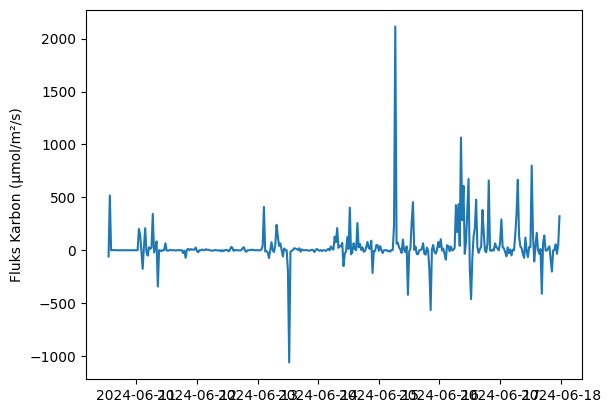

In [ ]:
# Menampilkan visualisasi
plt.plot(final_flux['C02_flux (μmol/m²/s)'])
plt.ylabel('Fluks Karbon (μmol/m²/s)')
plt.show()

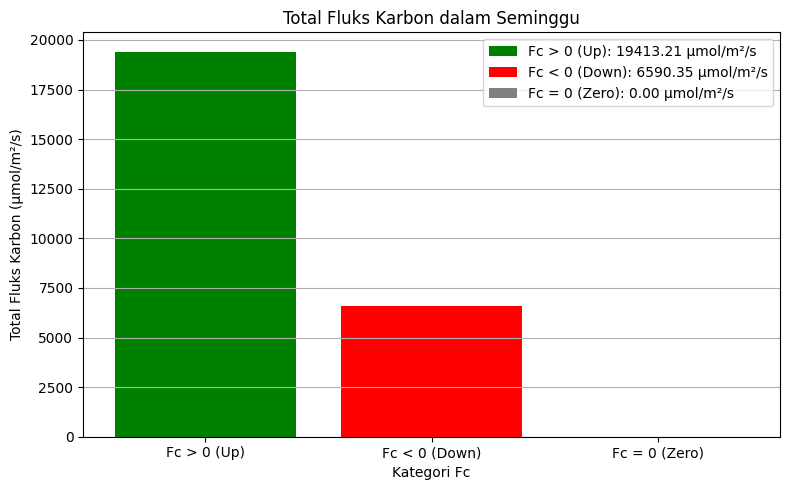

In [ ]:
# Ambil kolom Fc
Fc = final_flux['C02_flux (μmol/m²/s)']

# Hitung total nilai Fc untuk masing-masing kategori
Fc_pos_sum = Fc[Fc > 0].sum()
Fc_neg_sum = -Fc[Fc < 0].sum()  # Ambil nilai absolut
Fc_zero_sum = Fc[Fc == 0].sum()

# Data untuk bar chart
labels = ['Fc > 0 (Up)', 'Fc < 0 (Down)', 'Fc = 0 (Zero)']
sums = [Fc_pos_sum, Fc_neg_sum, Fc_zero_sum]
colors = ['green', 'red', 'gray']

# Plot bar chart
plt.figure(figsize=(8, 5))

bars = []
legend_labels = []

# Buat bar satu per satu dan kaitkan dengan labelnya
for label, total, color in zip(labels, sums, colors):
    bar = plt.bar(label, total, color=color, label=f"{label}: {total:.2f} μmol/m²/s")
    bars.append(bar)

# Tambahkan legenda (dari label di setiap bar)
plt.legend(loc='upper right')

# Tambahan info
plt.title('Total Fluks Karbon dalam Seminggu')
plt.ylabel('Total Fluks Karbon (μmol/m²/s)')
plt.xlabel('Kategori Fc')
plt.grid(axis='y')
plt.tight_layout()
plt.show()

**Visualisasi data Licor**

In [ ]:
licor = pd.read_csv("E:/KP RAFI RIDHO RAMADHAN/Data/data.csv")

licor.head()

,fluks_licor
0,120.188
1,172.375
2,677.048
3,16.939
4,164.982


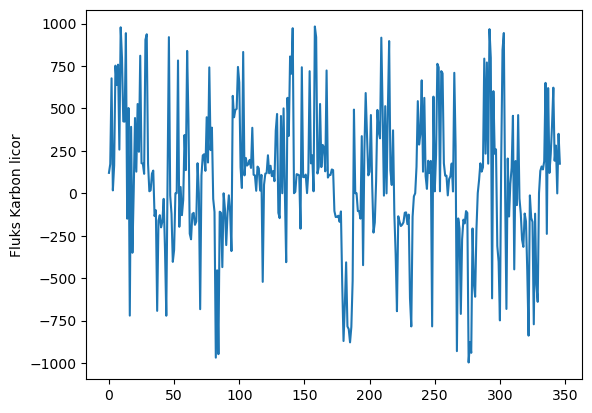

In [ ]:
# Menampilkan visualisasi
plt.plot(licor['fluks_licor'])
plt.ylabel('Fluks Karbon licor')
plt.show()

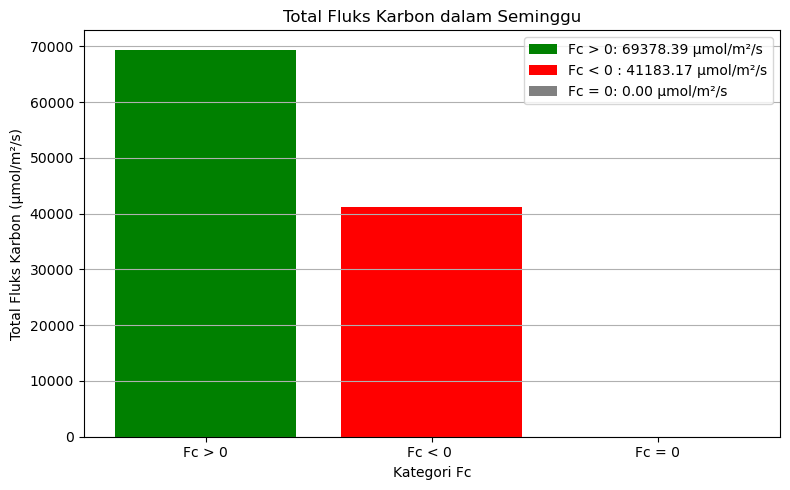

In [ ]:
# Ambil kolom Fc
licor = licor['fluks_licor']


# Hitung total nilai Fc untuk masing-masing kategori
Fc_pos_sum = licor[licor > 0].sum()
Fc_neg_sum = -licor[licor < 0].sum()
Fc_zero_sum = licor[licor == 0].sum()

# Data untuk bar chart
labels = ['Fc > 0', 'Fc < 0 ', 'Fc = 0']
sums = [Fc_pos_sum, Fc_neg_sum, Fc_zero_sum]

# Plot bar chart
plt.figure(figsize=(8, 5))

bars = []
legend_labels = []

# Buat bar satu per satu dan kaitkan dengan labelnya
for label, total, color in zip(labels, sums, colors):
    bar = plt.bar(label, total, color=color, label=f"{label}: {total:.2f} μmol/m²/s")
    bars.append(bar)

# Tambahkan legenda (dari label di setiap bar)
plt.legend(loc='upper right')

# Tambahan info
plt.title('Total Fluks Karbon dalam Seminggu')
plt.ylabel('Total Fluks Karbon (μmol/m²/s)')
plt.xlabel('Kategori Fc')
plt.grid(axis='y')
plt.tight_layout()
plt.show()

**Visualisasi Perhitungan Fluks Kak Irgi**

In [ ]:
kak_irgi = pd.read_csv("E:/KP RAFI RIDHO RAMADHAN/Fec_perdetik.csv")

kak_irgi.head(20)

,timestamp,bmp388Pressure,sht85Humi,sht85Temp,co2,bawah,atas,w,w_30m,w_aksen,p_H2O_sat,RH_decimal,p_H2O,x_H2O,co2_dry,co2_dry_30m,co2_dry_aksen,dry_pressure,Fec
0,2024-06-10 00:06:01,94.939728,93.432518,25.907911,457.000000,0.025559,0.000000,-0.025559,-0.017209,-0.008350,3.336997,0.934325,3.117843,0.033156,472.677872,473.764525,-1.086653,91.821885,0.006358
1,2024-06-10 00:06:02,99.238525,93.438876,25.907020,457.000000,0.079437,0.046667,-0.032771,-0.002278,-0.030493,3.336820,0.934389,3.117888,0.031418,471.823902,472.342324,-0.518422,96.120637,0.002544
2,2024-06-10 00:06:03,98.883162,93.424126,25.911472,457.000000,0.016418,0.000000,-0.016418,-0.029582,0.013164,3.337698,0.934241,3.118216,0.031535,471.880556,472.133926,-0.253371,95.764946,-0.000982
3,2024-06-10 00:06:04,99.118097,93.453880,25.930165,457.000000,0.020834,0.000000,-0.020834,-0.022998,0.002164,3.341399,0.934539,3.122667,0.031505,471.866002,472.058647,-0.192645,95.995429,-0.000030
4,2024-06-10 00:06:05,99.003197,93.415951,25.910198,457.714286,0.162485,0.000000,-0.162485,-0.044941,-0.117544,3.337445,0.934160,3.117706,0.031491,472.596863,472.088477,0.508386,95.885491,-0.024127
5,2024-06-10 00:06:06,99.142072,93.411410,25.909245,458.000000,0.111252,0.000000,-0.111252,-0.065835,-0.045418,3.337258,0.934114,3.117379,0.031444,472.868822,472.237377,0.631445,96.024693,-0.013174
6,2024-06-10 00:06:07,99.055558,93.436078,25.913697,458.000000,0.033434,0.000000,-0.033434,-0.062606,0.029171,3.338137,0.934361,3.119025,0.031488,472.890362,472.337360,0.553002,95.936533,0.006826
7,2024-06-10 00:06:08,99.053024,93.433790,25.927940,458.000000,0.035076,0.000000,-0.035076,-0.058215,0.023139,3.340954,0.934338,3.121580,0.031514,472.903242,472.410965,0.492277,95.931444,0.004925
8,2024-06-10 00:06:09,99.076754,93.412427,25.932391,458.000000,0.230730,0.000000,-0.230730,-0.073772,-0.156958,3.341835,0.934124,3.121689,0.031508,472.900135,472.468057,0.432079,95.955066,-0.028317
9,2024-06-10 00:06:10,99.259235,93.421328,25.918147,458.000000,0.139412,0.000000,-0.139412,-0.079761,-0.059651,3.339017,0.934213,3.119353,0.031426,472.860331,472.510399,0.349932,96.139881,-0.008171


In [ ]:
# Mengubah "Timestamp" menjadi indeks
kak_irgi['timestamp'] = pd.to_datetime(kak_irgi['timestamp'])
kak_irgi = kak_irgi.set_index("timestamp")
kak_irgi = kak_irgi.sort_index()

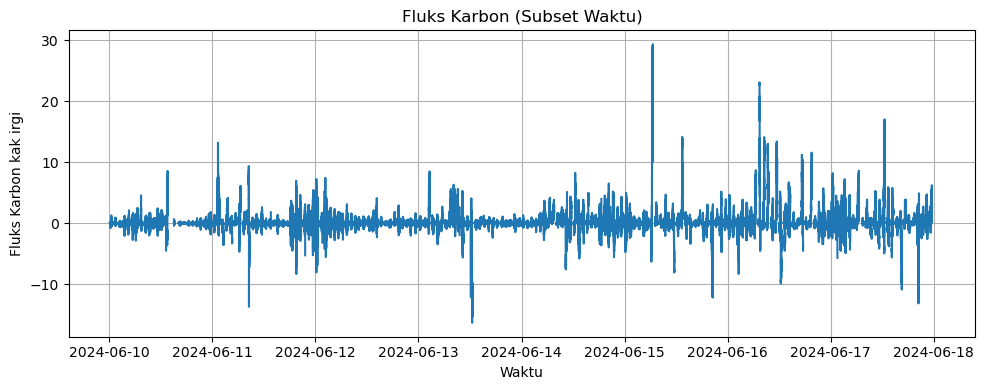

In [ ]:
# Tentukan rentang waktu
start_time = '2024-06-10 00:06:01'
end_time   = '2024-06-18 00:06:01'

# Filter data sesuai rentang
filtered = kak_irgi.loc[start_time:end_time]

# Tampilkan plot
plt.figure(figsize=(10, 4))
plt.plot(filtered['Fec'])
plt.ylabel('Fluks Karbon kak irgi')
plt.xlabel('Waktu')
plt.title('Fluks Karbon (Subset Waktu)')
plt.grid(True)
plt.tight_layout()
plt.show()

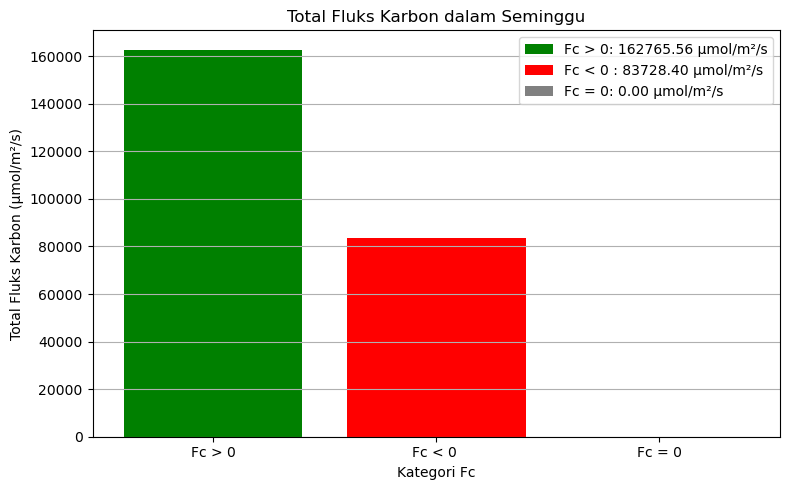

In [ ]:
kakirgi = filtered['Fec']

# Hitung total nilai Fc untuk masing-masing kategori
Fc_pos_sum = kakirgi[kakirgi > 0].sum()
Fc_neg_sum = -kakirgi[kakirgi < 0].sum()
Fc_zero_sum = kakirgi[kakirgi == 0].sum()

# Data untuk bar chart
labels = ['Fc > 0', 'Fc < 0 ', 'Fc = 0']
sums = [Fc_pos_sum, Fc_neg_sum, Fc_zero_sum]

# Plot bar chart
plt.figure(figsize=(8, 5))

bars = []
legend_labels = []

# Buat bar satu per satu dan kaitkan dengan labelnya
for label, total, color in zip(labels, sums, colors):
    bar = plt.bar(label, total, color=color, label=f"{label}: {total:.2f} μmol/m²/s")
    bars.append(bar)

# Tambahkan legenda (dari label di setiap bar)
plt.legend(loc='upper right')

# Tambahan info
plt.title('Total Fluks Karbon dalam Seminggu')
plt.ylabel('Total Fluks Karbon (μmol/m²/s)')
plt.xlabel('Kategori Fc')
plt.grid(axis='y')
plt.tight_layout()
plt.show()

# Menyimpan Data

In [ ]:
# Simpan data ke csv
final_flux.to_csv('/content/drive/MyDrive/Data Fluks/Hasil/data_coba.csv')